# 실습 3. 언어모델 바꿔 보기: 같은 문제, 다른 모델
**통계청 AI 교육 · 2026.10.27(화)**

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/sunghoonim/stat-ai-2026/blob/main/lab3_language_models.ipynb)

### 오늘의 목표
- 실제 한국어 문장(뉴스 기사 제목)으로 **언어모델을 바꿔 끼우며** 정확도·속도를 비교한다
- **라벨이 몇 개 있어야** 하는지, 사람이 정한 특징(글자 빈도)과 사전학습 모델을 비교한다
- 틀린 문장을 직접 읽어 보고, **정답 자체가 애매한 경우**를 확인한다
- 통계청 통계분류 자동화와 같은 방식인 **미세조정(fine-tuning)**을 해 본다
- 실습 1의 **산업분류**에 모델을 바꿔 다시 적용한다

| 단계 | 내용 | 시간 |
|---|---|---|
| 1단계 | 데이터 보기: 뉴스 제목 → 7개 분야 | 2분 |
| 2단계 | 기준선: 글자 조각 빈도(TF-IDF) + 로지스틱 회귀 | 3분 |
| 3단계 | 사전학습 모델 바꿔 끼우기 (KURE는 선택) | 5분 |
| 4단계 | 라벨 몇 개면 될까? | 3분 |
| 5단계 | 어디서 틀리나: 정답이 애매한 문장 | 3분 |
| 6단계 | 미세조정: 모델 전체를 다시 학습 | 5분 |
| 7단계 | 산업분류에 다시 적용 | 4분 |

**합계 25분** · 실습 1 다음에 실습 2~4 중 1~2개를 골라서 합니다. 오래 걸리는 칸은 저장된 결과를 보면 됩니다.

### 사용법
1. 메뉴 **런타임 → 런타임 유형 변경 → CPU**로 충분합니다. GPU(T4)가 있으면 6단계가 빨라집니다.
2. 메뉴 **런타임 → 모두 실행**. 처음에는 모델을 내려받느라 몇 분 걸립니다(모델 1개 0.5~1GB).
3. 이 노트북에는 **실행 결과가 미리 저장되어 있습니다.** 실행이 막혀도 결과를 보며 따라오세요. 다시 실행하면 숫자가 조금 다를 수 있습니다.
4. 그림 속 글자는 영어입니다. Colab 기본 글꼴에 한글이 없어서 그렇습니다.

## 0. 준비

In [1]:
#@title 필요한 도구 설치 확인 (Colab에 없으면 설치, 약 30초)
import subprocess, sys
try:
    import sentence_transformers
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "sentence-transformers"], check=True)

In [2]:
import warnings; warnings.filterwarnings("ignore")
import time, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import sklearn, transformers
from sklearn.linear_model import LogisticRegression
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import confusion_matrix
from sentence_transformers import SentenceTransformer

SEED = 0
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
device = "cuda" if torch.cuda.is_available() else "cpu"
transformers.logging.set_verbosity_error()          # 모델을 불러올 때 나오는 긴 안내문 숨기기
t_start = time.time()
print("PyTorch", torch.__version__, "| transformers", transformers.__version__,
      "| scikit-learn", sklearn.__version__, "| device:", device)

PyTorch 2.14.1 | transformers 5.20.1 | scikit-learn 1.9.1 | device: cpu


In [3]:
#@title 🎨 그림·기록 도우미 함수 (실행만 하세요)
plt.rcParams.update({"figure.dpi": 90})
TOPICS = ["IT과학", "경제", "사회", "생활문화", "세계", "스포츠", "정치"]
TOPICS_EN = ["IT/Science", "Economy", "Society", "Life/Culture", "World", "Sports", "Politics"]

def plot_confusion(y_true, y_pred, title=""):
    cm = confusion_matrix(y_true, y_pred, labels=range(7))
    fig, ax = plt.subplots(figsize=(4.8, 4.2))
    ax.imshow(cm, cmap="Blues")
    for i in range(7):
        for j in range(7):
            ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=8,
                    color="white" if cm[i, j] > cm.max() / 2 else "black")
    ax.set_xticks(range(7)); ax.set_xticklabels(TOPICS_EN, rotation=45, ha="right", fontsize=8)
    ax.set_yticks(range(7)); ax.set_yticklabels(TOPICS_EN, fontsize=8)
    ax.set_xlabel("predicted"); ax.set_ylabel("true"); ax.set_title(title, fontsize=10)
    fig.tight_layout(); plt.show()

scores = {}
def record(name, acc, n_labels, seconds):
    scores[name] = {"평가 정확도": acc, "사용한 라벨 수": n_labels, "걸린 시간(초)": seconds}
    print(f"{name}: 정확도 {acc:.1%} | 라벨 {n_labels:,}개 | {seconds:.0f}초")

---
## 1단계. 🟦 데이터 보기: 뉴스 제목 → 7개 분야 (2분)
**KLUE-YNAT**: 한국어 AI 평가용 공개 데이터(KLUE, 2021) 중 하나로, **연합뉴스 기사 제목**에 7개 분야 정답이 붙어 있습니다. (CC BY-SA 4.0)
분야마다 **학습용 200개, 평가용 100개**만 뽑아 씁니다. 짧은 자유 문장을 정해진 분류에 넣는다는 점에서, 조사표 자유 응답을 분류 코드에 배정하는 일과 구조가 같습니다.

In [4]:
#@title 데이터 내려받기 (약 5MB)
URL = "https://huggingface.co/datasets/klue/klue/resolve/main/ynat/{}-00000-of-00001.parquet"
ynat_train = pd.read_parquet(URL.format("train"))
ynat_valid = pd.read_parquet(URL.format("validation"))
print(f"원본: 학습용 {len(ynat_train):,}개 | 검증용 {len(ynat_valid):,}개")

# 분야마다 학습용 200개, 평가용 100개 (층화추출)
pool = ynat_train.groupby("label").sample(200, random_state=SEED).reset_index(drop=True)
test = ynat_valid.groupby("label").sample(100, random_state=SEED).reset_index(drop=True)
y_pool, y_test = pool["label"].to_numpy(), test["label"].to_numpy()
print(f"이 실습: 학습용 {len(pool):,}개 | 평가용 {len(test)}개 | 분야 7개 → 아무렇게나 찍으면 약 14%")

pool.assign(분야=pool["label"].map(dict(enumerate(TOPICS))))[["title", "분야"]] \
    .groupby("분야").head(2).rename(columns={"title": "기사 제목"}).sort_values("분야").reset_index(drop=True)

원본: 학습용 45,678개 | 검증용 9,107개
이 실습: 학습용 1,400개 | 평가용 700개 | 분야 7개 → 아무렇게나 찍으면 약 14%


,기사 제목,분야
0,영상 삼성 갤럭시노트10 9일부터 국내 사전판매…23일 정식 출시,IT과학
1,페이스북 삭제 캠페인 작동했나…미국인 9% 계정 삭제,IT과학
2,KB증권 우리은행 지주사 추진 주가에 긍정적,경제
3,국내 주식형 펀드 12일 만에 자금 순유입,경제
4,10년 후 한국의 가장 중요한 이슈는…저출산·초고령화,사회
5,성명서 발표 마친 핵무기연구소 부소장,사회
6,물놀이·공연 그리고 게임…부산바다축제 내달 1일 팡파르,생활문화
7,답사기 중국편 쓴 유홍준 실크로드 만든 힘은 돈과 종교,생활문화
8,中 공산당 중앙정치국 회의서 경기 부양 의지 재확인,세계
9,中환구시보 美 신미사일방어전략 북미 核담판에 도움 안돼,세계


---
## 2단계. 기준선: 글자 조각 빈도(TF-IDF) + 로지스틱 회귀 (3분)
사전학습 모델 없이, **사람이 정한 특징**으로 먼저 해 봅니다. 제목을 2~3글자 조각으로 잘라 조각마다 빈도를 셉니다(TF-IDF). 그 위에 다항 로지스틱 회귀를 얹습니다.

In [5]:
t = time.time()
tfidf = TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 3)).fit(pool["title"])
T_pool, T_test = tfidf.transform(pool["title"]), tfidf.transform(test["title"])
print(f"특징 수: {T_pool.shape[1]:,}개 (글자 조각 종류)")
print("예: '반도체 수출 증가' →", [w for w in tfidf.build_analyzer()("반도체 수출 증가")][:10], "...")

clf_tfidf = LogisticRegression(C=10, max_iter=5000).fit(T_pool, y_pool)
record("TF-IDF + 로지스틱 회귀", clf_tfidf.score(T_test, y_test), len(pool), time.time() - t)

특징 수: 29,460개 (글자 조각 종류)
예: '반도체 수출 증가' → [' 반', '반도', '도체', '체 ', ' 반도', '반도체', '도체 ', ' 수', '수출', '출 '] ...


TF-IDF + 로지스틱 회귀: 정확도 70.9% | 라벨 1,400개 | 0초


> ✅ 7개 중 찍으면 14%인데 70% 안팎을 맞힙니다. 이미 쓸 만한 기준선입니다. 새 모델은 **항상 이런 단순한 기준선과 같이** 비교합니다.

---
## 3단계. 사전학습 모델 바꿔 끼우기 (5분)
이번에는 문장을 **사전학습 모델이 만든 숫자 벡터**로 바꾸고, 그 위에 **똑같은 로지스틱 회귀**를 얹습니다. **모델만 바꾸고 나머지는 모두 같게** 둡니다.

| 모델 | 가중치 수 | 특징 |
|---|---|---|
| `jhgan/ko-sroberta-multitask` | 약 1.1억 | 실습 1에서 쓴 모델. **한국어 전용** RoBERTa |
| `intfloat/multilingual-e5-small` | 약 1.2억 | **100개 언어**로 학습한 다국어 모델. 작고 빠름 (숫자 384개) |
| `intfloat/multilingual-e5-base` | 약 2.8억 | 같은 계열의 더 큰 모델 |

모델마다 두 가지를 잽니다.
- **zero-shot**: 분야 이름("IT과학 분야 뉴스" …)과 가장 가까운 분야를 고름. 라벨 0개
- **라벨 1,400개**: 임베딩 + 로지스틱 회귀

In [6]:
MODELS = {   # 모델 이름: 문장 앞에 붙일 말 (e5 계열은 'query: '를 붙이도록 학습됨)
    "jhgan/ko-sroberta-multitask": "",
    "intfloat/multilingual-e5-small": "query: ",
    "intfloat/multilingual-e5-base": "query: ",
}
LABEL_TEXTS = [f"{t} 분야 뉴스" for t in TOPICS]

def evaluate_embedder(name, prefix=""):
    model = SentenceTransformer(name, device=device)
    enc = lambda texts: model.encode([prefix + s for s in texts], normalize_embeddings=True,
                                     batch_size=64, show_progress_bar=False)
    t = time.time()
    E_pool, E_test = enc(pool["title"]), enc(test["title"])
    speed = (len(pool) + len(test)) / (time.time() - t)
    zs = ((E_test @ enc(LABEL_TEXTS).T).argmax(1) == y_test).mean()
    acc = LogisticRegression(C=1, max_iter=5000).fit(E_pool, y_pool).score(E_test, y_test)
    row = {"가중치 수(백만)": sum(p.numel() for p in model.parameters()) / 1e6, "벡터 길이": E_pool.shape[1],
           "초당 문장 수": speed, "zero-shot (라벨 0개)": zs, "로지스틱 (라벨 1,400개)": acc}
    print(f"{name}: zero-shot {zs:.1%} | 로지스틱 {acc:.1%} | 초당 {speed:.0f}문장")
    return row, model, (E_pool, E_test)

compare, embedders, emb = {}, {}, {}
for name, prefix in MODELS.items():
    compare[name], embedders[name], emb[name] = evaluate_embedder(name, prefix)

def show_compare():
    return pd.DataFrame(compare).T.style.format({
        "가중치 수(백만)": "{:.0f}", "벡터 길이": "{:.0f}", "초당 문장 수": "{:.0f}",
        "zero-shot (라벨 0개)": "{:.1%}", "로지스틱 (라벨 1,400개)": "{:.1%}"}).background_gradient(
        cmap="Greens", subset=["zero-shot (라벨 0개)", "로지스틱 (라벨 1,400개)"])
show_compare()

jhgan/ko-sroberta-multitask: zero-shot 47.6% | 로지스틱 77.0% | 초당 241문장


intfloat/multilingual-e5-small: zero-shot 62.3% | 로지스틱 78.6% | 초당 468문장


intfloat/multilingual-e5-base: zero-shot 65.1% | 로지스틱 81.0% | 초당 183문장


,가중치 수(백만),벡터 길이,초당 문장 수,zero-shot (라벨 0개),"로지스틱 (라벨 1,400개)"
jhgan/ko-sroberta-multitask,111,768,241,47.6%,77.0%
intfloat/multilingual-e5-small,118,384,468,62.3%,78.6%
intfloat/multilingual-e5-base,278,768,183,65.1%,81.0%


### 3-1. (선택) 더 큰 한국어 특화 모델
`nlpai-lab/KURE-v1`(고려대, 약 5.7억 개)은 다국어 대형 모델(BGE-M3)을 한국어 검색용으로 더 학습한 모델입니다. 내려받기 2.3GB, CPU에서 3~5분 걸립니다. 시간이 없으면 건너뛰고 저장된 결과만 보세요.

In [7]:
compare["nlpai-lab/KURE-v1"], _, _ = evaluate_embedder("nlpai-lab/KURE-v1")
show_compare()

nlpai-lab/KURE-v1: zero-shot 65.3% | 로지스틱 81.9% | 초당 60문장


,가중치 수(백만),벡터 길이,초당 문장 수,zero-shot (라벨 0개),"로지스틱 (라벨 1,400개)"
jhgan/ko-sroberta-multitask,111,768,241,47.6%,77.0%
intfloat/multilingual-e5-small,118,384,468,62.3%,78.6%
intfloat/multilingual-e5-base,278,768,183,65.1%,81.0%
nlpai-lab/KURE-v1,568,1024,60,65.3%,81.9%


> ✅ **확인할 것**
> - **같은 로지스틱 회귀**인데 특징(모델)만 바꿔도 정확도가 달라집니다. 사전학습 모델은 모두 TF-IDF(2단계)보다 낫습니다.
> - 실습 1에서 쓴 한국어 전용 모델보다 **다국어 모델(e5)이 더 나을 수 있습니다.** '한국어 전용'이 항상 이기지는 않습니다. 무엇으로, 어떤 목적(문장 유사도, 검색 등)으로 학습했느냐가 중요합니다.
> - **크다고 비례해서 좋아지지 않습니다.** e5-base → KURE는 가중치가 2배인데 정확도는 1%p 안팎 차이이고 속도는 3분의 1 수준입니다. 같은 일을 매일 수십만 건 처리한다면 속도가 곧 비용입니다.
> - e5-small은 정확도는 조금 낮지만 **가장 빠릅니다.** 정확도와 속도 사이에서 고르는 문제입니다.
> - zero-shot은 분야 이름만으로 50~65% 안팎입니다. 이름만으로는 '사회'와 '생활문화'의 경계를 알 수 없습니다.

---
## 4단계. 라벨 몇 개면 될까? (3분)
분야마다 라벨을 **5, 10, 20, 50, 100, 200개**만 주고 비교합니다. 같은 개수라도 어떤 문장이 뽑히느냐에 따라 결과가 달라지므로 **3번 반복해 평균**을 냅니다.

2초


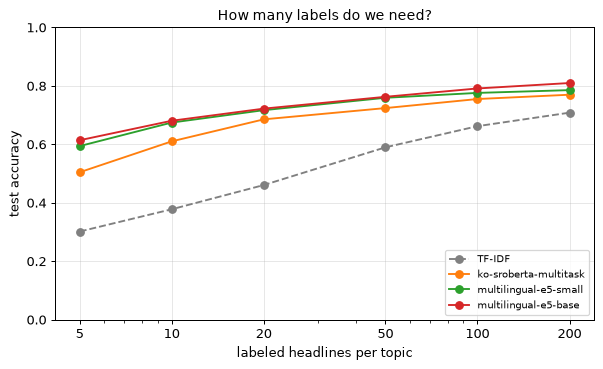

,5개,10개,20개,50개,100개,200개
TF-IDF,30.2%,37.8%,46.1%,59.0%,66.2%,70.9%
ko-sroberta-multitask,50.5%,61.0%,68.6%,72.4%,75.5%,77.0%
multilingual-e5-small,59.4%,67.5%,71.7%,76.0%,77.6%,78.6%
multilingual-e5-base,61.4%,68.1%,72.2%,76.3%,79.1%,81.0%


In [8]:
K_LIST = [5, 10, 20, 50, 100, 200]

def label_curve(make_clf, F_pool, F_test, repeats=3):
    out = []
    for k in K_LIST:
        accs = []
        for r in range(repeats if k < 200 else 1):
            idx = pool.groupby("label").sample(k, random_state=r).index.to_numpy()
            if hasattr(F_pool, "tocsr"):            # TF-IDF는 고른 문장으로 다시 글자 조각을 셈
                vec = TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 3)).fit(pool["title"][idx])
                Ftr, Fte = vec.transform(pool["title"][idx]), vec.transform(test["title"])
            else:
                Ftr, Fte = F_pool[idx], F_test
            accs.append(make_clf().fit(Ftr, y_pool[idx]).score(Fte, y_test))
        out.append(np.mean(accs))
    return pd.Series(out, index=K_LIST)

t = time.time()
curves = {"TF-IDF": label_curve(lambda: LogisticRegression(C=10, max_iter=5000), T_pool, T_test)}
for name in MODELS:
    curves[name.split("/")[1]] = label_curve(lambda: LogisticRegression(C=1, max_iter=5000), *emb[name])
print(f"{time.time() - t:.0f}초")

fig, ax = plt.subplots(figsize=(6.8, 4.2))
for i, (name, c) in enumerate(curves.items()):
    ax.plot(c.index, c.values, marker="o", ls="--" if name == "TF-IDF" else "-", color="gray" if name == "TF-IDF" else f"C{i}", label=name)
ax.set_xscale("log"); ax.set_xticks(K_LIST); ax.set_xticklabels(K_LIST)
ax.set_xlabel("labeled headlines per topic"); ax.set_ylabel("test accuracy"); ax.set_ylim(0, 1)
ax.grid(alpha=0.3); ax.legend(fontsize=8, loc="lower right"); ax.set_title("How many labels do we need?", fontsize=11)
plt.tight_layout(); plt.show()
pd.DataFrame(curves).T.rename(columns=lambda k: f"{k}개").style.format("{:.1%}")

> ✅ **확인할 것**
> - 라벨이 적을수록 **사전학습 모델과 TF-IDF의 차이가 큽니다.** 분야마다 5~10개일 때 TF-IDF는 찍는 수준에 가깝지만, 사전학습 모델은 이미 쓸 만합니다.
> - TF-IDF는 라벨이 늘면 계속 따라옵니다. **라벨이 아주 많으면** 단순한 방법과의 차이가 줄어듭니다.
> - 실무에서 라벨은 비쌉니다. **라벨 예산이 적을수록 사전학습 모델의 가치가 큽니다.** (실습 2의 위성영상과 같은 결론)

---
## 5단계. 어디서 틀리나: 정답이 애매한 문장 (3분)
가장 나았던 모델로 틀린 문장을 직접 읽어 봅니다.

모델: intfloat/multilingual-e5-base


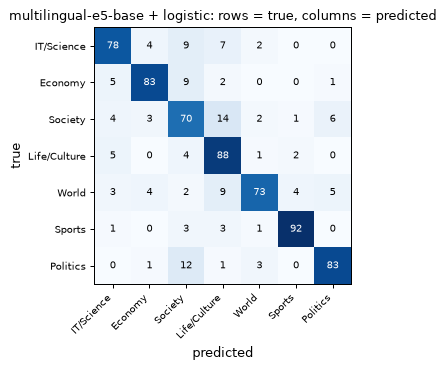

In [9]:
best = max(MODELS, key=lambda n: compare[n]["로지스틱 (라벨 1,400개)"])
E_pool, E_test = emb[best]
clf_best = LogisticRegression(C=1, max_iter=5000).fit(E_pool, y_pool)
pred, proba = clf_best.predict(E_test), clf_best.predict_proba(E_test)
print("모델:", best)
plot_confusion(y_test, pred, f"{best.split('/')[1]} + logistic: rows = true, columns = predicted")

In [10]:
wrong = test.assign(정답=[TOPICS[i] for i in y_test], 예측=[TOPICS[i] for i in pred],
                    확률=proba.max(1))[pred != y_test]
print(f"틀린 문장 {len(wrong)}개 중 확률이 높았던(자신 있게 틀린) 것 10개")
wrong.sort_values("확률", ascending=False)[["title", "정답", "예측", "확률"]].head(10) \
     .rename(columns={"title": "기사 제목"}).style.format({"확률": "{:.0%}"})

틀린 문장 133개 중 확률이 높았던(자신 있게 틀린) 것 10개


,기사 제목,정답,예측,확률
165,구글 순정 OS 담은 스마트폰 LG Q9 원 15일 출시,경제,IT과학,75%
146,스카이 무선이어폰 인기…초도 수량 3일 만에 완판,경제,IT과학,62%
327,이젠 스마트폰이 효도폰…SKT 노년 고객 74% 스마트폰 사용,생활문화,IT과학,56%
421,미국 컨슈머리포트 삼성 기어S3 애플워치보다 나아,세계,IT과학,50%
484,日·臺 프리미어12 개막전서 베네수·푸에르토 제압,세계,스포츠,49%
271,SK 서린동 본사 구글·페이스북 사무실처럼 바뀐다,사회,IT과학,49%
400,북미 냉기류 속 시진핑 4월 남북한 동시답방설 솔솔종합,세계,정치,48%
412,카파도키아 찾은 관광객들,세계,생활문화,47%
650,정부의 노조법 개정 반대 기자회견,정치,사회,45%
422,강서경 스위스 아트바젤서 발루아즈상 수상,세계,생활문화,44%


> ✅ **확인할 것**
> - 헷갈림의 중심은 **'사회'**입니다. 사회 → 생활문화, 정치 → 사회, 경제·IT과학 → 사회. 범위가 넓은 분류일수록 경계가 흐립니다.
> - 위 표의 제목을 읽어 보세요. **모델의 답도 그럴듯한** 경우가 꽤 있지 않나요? 기사 하나가 여러 분야에 걸치거나, 사람이 붙인 정답이 애매한 경우입니다.
> - 통계분류도 같습니다. **분류 지침이 명확해야** 사람도 모델도 일관되게 분류합니다. 모델이 자신 있게 틀린 건을 모아 보면 **지침의 빈틈이나 라벨 오류**를 찾는 데도 쓸 수 있습니다.

---
## 6단계. 미세조정: 모델 전체를 다시 학습 (5분)
지금까지는 사전학습 모델을 **고정**하고 그 위의 로지스틱 회귀만 학습했습니다. **미세조정(fine-tuning)**은 사전학습 모델의 **가중치까지 우리 데이터에 맞게 조금씩 고칩니다.**
7교시에 소개할 통계청 통계분류 자동화 시스템(RoBERTa)이 이 방식입니다.

모델: `klue/roberta-small` (KLUE 연구진이 공개한 한국어 RoBERTa, 6층, 약 6,800만 개)
- 🟦 **Data:** 제목 → 토큰 번호 (최대 32개)
- 🟩 **Model:** 사전학습 RoBERTa + **새로 붙인 분류층**(7개 분야)
- 🟧 **Loss:** 교차엔트로피 (다항 로지스틱의 음의 로그우도)
- 🟥 **Optimizer:** AdamW, 학습률 0.00005. 이미 배운 것을 망가뜨리지 않도록 **아주 작게** 움직입니다.

⏱️ CPU에서 2~4분 걸립니다(GPU면 30초 안팎).

In [11]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification

FT_NAME = "klue/roberta-small"
tokenizer = AutoTokenizer.from_pretrained(FT_NAME)
print("토큰으로 자르기:", tokenizer.tokenize("통계청, 3분기 고용동향 발표…취업자 증가 지속"))

# 🟦 Data: 제목 → 토큰 번호
enc = lambda texts: tokenizer(list(texts), padding=True, truncation=True, max_length=32, return_tensors="pt")
X_pool, X_test = enc(pool["title"]), enc(test["title"])
Y_pool = torch.tensor(y_pool)

# 🟩 Model: 사전학습 RoBERTa + 분류층 7개 (분류층만 무작위로 시작)
torch.manual_seed(SEED)
ft_model = AutoModelForSequenceClassification.from_pretrained(FT_NAME, num_labels=7).to(device)
print(f"가중치 수: {sum(p.numel() for p in ft_model.parameters()) / 1e6:.0f}백만 개 (전부 학습 대상)")
# 🟥 Optimizer: AdamW, 작은 학습률
optimizer = torch.optim.AdamW(ft_model.parameters(), lr=5e-5)

@torch.no_grad()
def ft_predict(X, batch_size=128):
    ft_model.eval()
    return torch.cat([ft_model(input_ids=X["input_ids"][i:i + batch_size].to(device),
                               attention_mask=X["attention_mask"][i:i + batch_size].to(device)).logits.argmax(1).cpu()
                      for i in range(0, len(X["input_ids"]), batch_size)]).numpy()

t = time.time()
for epoch in range(2):
    ft_model.train()
    perm = torch.randperm(len(Y_pool))
    for i in range(0, len(perm), 32):                         # 32개씩 미니배치
        b = perm[i:i + 32]
        out = ft_model(input_ids=X_pool["input_ids"][b].to(device), attention_mask=X_pool["attention_mask"][b].to(device),
                       labels=Y_pool[b].to(device))           # 🟧 labels를 주면 교차엔트로피를 계산해 줌
        optimizer.zero_grad()
        out.loss.backward()                                   # 역전파: 1억 개 가까운 가중치의 기울기
        optimizer.step()
    print(f"epoch {epoch + 1} | 평가 정확도 {(ft_predict(X_test) == y_test).mean():.1%} | {time.time() - t:.0f}초")
record("미세조정 (klue/roberta-small)", (ft_predict(X_test) == y_test).mean(), len(pool), time.time() - t)

토큰으로 자르기: ['통계청', ',', '3', '##분', '##기', '고용', '##동', '##향', '발표', '…', '취업자', '증가', '지속']


가중치 수: 68백만 개 (전부 학습 대상)


epoch 1 | 평가 정확도 84.0% | 24초


epoch 2 | 평가 정확도 83.7% | 50초


미세조정 (klue/roberta-small): 정확도 83.7% | 라벨 1,400개 | 52초


In [12]:
summary = {"TF-IDF + 로지스틱 회귀": scores["TF-IDF + 로지스틱 회귀"]["평가 정확도"]}
summary.update({f"{n.split('/')[1]} (고정) + 로지스틱": compare[n]["로지스틱 (라벨 1,400개)"] for n in compare})
summary["klue/roberta-small 미세조정"] = scores["미세조정 (klue/roberta-small)"]["평가 정확도"]
pd.Series(summary, name="평가 정확도 (라벨 1,400개)").to_frame().style.format("{:.1%}") \
  .background_gradient(cmap="Greens")

,"평가 정확도 (라벨 1,400개)"
TF-IDF + 로지스틱 회귀,70.9%
ko-sroberta-multitask (고정) + 로지스틱,77.0%
multilingual-e5-small (고정) + 로지스틱,78.6%
multilingual-e5-base (고정) + 로지스틱,81.0%
KURE-v1 (고정) + 로지스틱,81.9%
klue/roberta-small 미세조정,83.7%


> ✅ **확인할 것**
> - 미세조정한 모델은 **가장 작은 모델**인데도, 고정한 큰 모델 + 로지스틱 회귀와 비슷하거나 더 높습니다. 모델 전체가 **이 과제에 맞게** 바뀌었기 때문입니다.
> - 대신 비용이 듭니다. 학습 시간이 길고(GPU 권장), 과제마다 모델을 따로 저장·관리해야 하고, 과적합도 조심해야 합니다.
> - 정리하면: **고정 + 로지스틱**은 싸고 빠른 출발점, **미세조정**은 라벨이 충분하고 성능이 중요할 때. 통계청 시스템처럼 **같은 일을 대량으로 오래** 한다면 미세조정할 가치가 있습니다.

---
## 7단계. 산업분류에 다시 적용 (4분)
실습 1의 **사업체 설명 80문장**(대분류 8개)에 3단계의 모델들을 바꿔 끼워 봅니다. 학습용 48문장, 평가용 32문장으로 나누는 방법은 실습 1과 같습니다.

In [13]:
#@title 실습 1의 사업체 설명 80문장 (실습용으로 만든 예시)
KSIC = {"C": "제조업", "F": "건설업", "G": "도매 및 소매업", "H": "운수 및 창고업",
        "I": "숙박 및 음식점업", "J": "정보통신업", "P": "교육 서비스업", "Q": "보건업 및 사회복지 서비스업"}
BIZ = {
    "C": ["자동차용 플라스틱 내장 부품을 사출 성형해 완성차 업체에 납품", "공장에서 김치를 대량 생산해 유통업체에 공급",
          "반도체 웨이퍼 세정 장비를 설계하고 제작", "원단을 재단하고 봉제해 여성 의류를 생산", "철판을 가공해 산업용 기계 부품을 만듦",
          "화장품 원료를 배합해 스킨케어 제품을 제조", "목재를 가공해 가정용 가구를 제작", "의약품 정제와 캡슐을 생산하는 제약 공장 운영",
          "사료 원료를 배합해 가축용 배합사료를 생산", "리튬이온 배터리 셀을 조립하고 생산"],
    "F": ["아파트 신축 공사의 골조 공사를 도급받아 시공", "도로 포장 및 보수 공사 수행", "상가와 주택의 실내 인테리어 공사, 도배, 바닥 시공",
          "건물 전기 배선과 조명 설비 공사", "상하수도 관로 매설 공사", "단독주택 리모델링 공사를 전문으로 시공", "교량과 터널 등 토목 공사 시공",
          "건물 냉난방 배관 설비 공사", "공장 건물의 철골 구조물 설치 공사", "노후 건물 철거 및 해체 공사"],
    "G": ["동네에서 편의점을 운영하며 식료품과 생활용품 판매", "온라인 쇼핑몰에서 여성 의류를 판매", "수입 와인을 들여와 식당과 주류 판매점에 공급",
          "중고 자동차를 매입해 판매", "휴대폰과 액세서리를 판매하는 매장 운영", "가전제품 전문 매장에서 TV와 냉장고 판매",
          "농산물 도매시장에서 과일을 경매받아 소매상에 납품", "철물과 공구를 건설 현장과 철물점에 도매로 공급", "꽃집을 운영하며 꽃다발과 화분 판매",
          "사무용품과 문구류를 기업에 납품하는 도매업"],
    "H": ["화물 트럭으로 기업 물품을 전국에 운송", "시내버스 노선 운행", "택배 물품을 집하해 가정으로 배송", "냉동 창고를 운영하며 식품을 보관",
          "개인택시로 승객 운송", "컨테이너 화물을 선박으로 해상 운송", "국제 항공 화물 운송을 주선하는 포워딩 업무", "이삿짐 포장과 운송 서비스",
          "고속버스 터미널 운영", "오토바이 퀵서비스로 서류와 소화물 배달"],
    "I": ["프랜차이즈 치킨 전문점 운영", "해변 근처에서 펜션 운영", "동네에서 한식 백반집 운영", "커피 전문점 운영", "비즈니스 호텔 운영",
          "회사 구내식당을 위탁받아 단체 급식 제공", "저녁에 맥주와 안주를 파는 호프집 운영", "피자를 만들어 배달 판매하는 피자 전문점",
          "외국인 관광객 대상 게스트하우스 운영", "분식집에서 김밥과 떡볶이 판매"],
    "J": ["스마트폰 앱과 웹 서비스 개발", "기업용 회계 소프트웨어 개발 및 판매", "모바일 게임 개발 및 서비스", "인터넷 포털 사이트 운영",
          "데이터센터에서 서버 호스팅 서비스 제공", "지역 신문 발행", "드라마와 예능 방송 프로그램 제작", "인터넷 회선과 이동통신 서비스 제공",
          "기업 전산 시스템 구축 및 유지보수", "라디오 방송국 운영"],
    "P": ["초등학생 대상 수학 학원 운영", "사립 초등학교 운영", "성인 대상 영어 회화 학원", "피아노 교습소 운영", "태권도장 운영",
          "자동차 운전 학원 운영", "4년제 대학교 운영", "코딩 교육 부트캠프 운영", "온라인으로 공무원 시험 강의 제공", "유치원 운영"],
    "Q": ["내과 의원 운영", "치과 의원 진료", "요양병원 운영", "노인 요양 시설 운영", "한의원 운영", "장애인 주간보호센터 운영",
          "종합병원 응급실과 입원 진료", "어르신 댁을 방문하는 방문 요양 서비스", "물리치료 재활 클리닉 운영", "건강검진 센터 운영"],
}
from sklearn.model_selection import train_test_split
biz = pd.DataFrame([(c, t) for c, texts in BIZ.items() for t in texts], columns=["code", "text"])
tr_df, te_df = train_test_split(biz, test_size=0.4, random_state=SEED, stratify=biz["code"])
codes = list(KSIC)
PUZZLES = ["약국을 운영하며 처방약과 일반의약품을 판매합니다", "어린이집을 운영하며 영유아를 보육합니다",
           "직접 구운 빵과 케이크를 매장에서 파는 동네 제과점입니다"]
PUZZLE_ANSWER = ["G", "Q", "I"]
print(f"학습용 {len(tr_df)}문장 | 평가용 {len(te_df)}문장 | 퍼즐 {len(PUZZLES)}문장")

학습용 48문장 | 평가용 32문장 | 퍼즐 3문장


In [14]:
rows = {}
for name, prefix in MODELS.items():
    m = embedders[name]
    enc_ = lambda texts: m.encode([prefix + s for s in texts], normalize_embeddings=True, show_progress_bar=False)
    E_tr, E_te, E_lab, E_puz = enc_(tr_df["text"]), enc_(te_df["text"]), enc_([KSIC[c] for c in codes]), enc_(PUZZLES)
    clf = LogisticRegression(C=10, max_iter=5000).fit(E_tr, tr_df["code"])
    puz = clf.predict(E_puz)
    rows[name] = {"zero-shot (분류명과 유사도)": (np.array(codes)[(E_te @ E_lab.T).argmax(1)] == te_df["code"].values).mean(),
                  "로지스틱 (48문장)": clf.score(E_te, te_df["code"]),
                  **{f"퍼즐: {p[:6]}… (정답 {a})": pz for p, a, pz in zip(PUZZLES, PUZZLE_ANSWER, puz)}}
pd.DataFrame(rows).T.style.format({"zero-shot (분류명과 유사도)": "{:.1%}", "로지스틱 (48문장)": "{:.1%}"})

,zero-shot (분류명과 유사도),로지스틱 (48문장),퍼즐: 약국을 운영… (정답 G),퍼즐: 어린이집을 … (정답 Q),퍼즐: 직접 구운 … (정답 I)
jhgan/ko-sroberta-multitask,93.8%,93.8%,G,P,G
intfloat/multilingual-e5-small,65.6%,84.4%,G,P,G
intfloat/multilingual-e5-base,59.4%,87.5%,G,P,I


> ✅ **확인할 것**
> - 3단계 뉴스 제목에서는 다국어 e5-base가 가장 좋았는데, **산업분류에서는 실습 1의 한국어 모델(ko-sroberta)이 가장 좋습니다.** 특히 zero-shot에서 차이가 큽니다.
> - **과제(데이터)가 바뀌면 모델 순위도 바뀝니다.** 남이 만든 순위표나 다른 과제의 결과로 고르지 말고, **우리 업무 데이터로 직접 재서** 고릅니다.
> - 퍼즐 세 문장(약국 → G, 어린이집 → Q, 제과점 → I)은 어떤가요? 저장된 결과에서는 약국은 모두 맞혔지만, 어린이집은 모두 교육(P)으로 틀렸고, 제과점은 모델마다 다릅니다. 모델을 바꿔도 **분류 지침의 예외 규칙**은 잘 모릅니다. 뜻이 비슷한지만 보기 때문입니다.

---
## 마무리
| 요소 | TF-IDF + 로지스틱 | 사전학습(고정) + 로지스틱 | 미세조정 |
|---|---|---|---|
| 🟦 **Data** | 글자 조각 빈도 (사람이 정한 특징) | 모델이 만든 숫자 384~1024개 | 토큰 번호 |
| 🟩 **Model** | 다항 로지스틱 | 사전학습 모델(고정) + 다항 로지스틱 | 사전학습 모델 + 분류층, **전부 학습** |
| 🟧 **Loss** | 교차엔트로피 + L2 벌점 | 교차엔트로피 + L2 벌점 | 교차엔트로피 |
| 🟥 **Optimizer** | L-BFGS | L-BFGS | AdamW (작은 학습률) |

### 오늘의 핵심
1. 모델을 바꾸면 정확도와 속도가 함께 바뀝니다. **크다고 항상 이기지 않고, 과제가 바뀌면 순위도 바뀝니다.** 우리 데이터로 직접 재 봐야 합니다.
2. **라벨이 적을수록** 사전학습 모델의 가치가 큽니다.
3. 틀린 사례를 읽어 보면 **분류 지침과 라벨의 문제**도 보입니다.
4. **고정 + 로지스틱**은 싸고 빠른 출발점, **미세조정**은 대량·장기 업무용입니다.

### 국가통계와의 연결
- 산업·직업분류, 품목분류, 민원·자유응답 분류처럼 **짧은 글 → 분류 코드** 업무에 그대로 쓰는 구조입니다.
- 모델을 고를 때는 **정확도, 처리 속도(=비용), 라벨 준비 비용, 보안(기관 안에서 돌릴 수 있는가)**을 함께 봅니다.
- 확률이 낮거나 지침의 예외에 해당하는 건은 **사람이 검토**하고, 그 결과를 다시 학습 데이터로 쌓습니다.

In [15]:
print(f"전체 실행 시간: {time.time() - t_start:.0f}초")

전체 실행 시간: 141초
